# Stress-testing benchmark portfolios

Held-out volatility and turnover are measured after each training window:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}
=\sqrt{252}\,\operatorname{sd}(R_k^{\mathrm{test}}w_{k,m}),
\qquad
\operatorname{turnover}_{k,m}
=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio method, $R_k^{\mathrm{test}}$ is the held-out daily return matrix, $w_{k,m}$ is chosen from the earlier training window, $\operatorname{sd}$ is sample standard deviation, 252 is the annualization count, and the one-norm adds absolute weight changes.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("23_portfolio_geometry");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using TOML
using RiskLabAI.Optimization: get_optimal_portfolio_weights
using RiskLabAI.Data: form_true_matrix
include(joinpath("..","support","BookPortfolioGeometry.jl"))
using .BookPortfolioGeometry
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))
function portfolio_record(name,weights,expected_return,covariance)
    return (Portfolio=name,expected=dot(weights,expected_return),volatility=sqrt(dot(weights,covariance*weights)),largest=maximum(weights),smallest=minimum(weights),gross=sum(abs,weights),concentration=sum(abs2,weights),effective=1/sum(abs2,weights))
end
function portfolio_table(records)
    frame = DataFrame(records)
    rename!(frame,["Portfolio","Expected annual return","Annual volatility","Largest long weight","Smallest weight","Gross exposure","Weight concentration","Effective holdings"])
    return frame
end
function weight_frame(weights;metadata...)
    frame = DataFrame([key=>fill(value,length(weights)) for (key,value) in pairs(metadata)]...)
    return hcat(frame,DataFrame(asset=1:length(weights),weight=weights))
end
function save_noise_fit(covariance,q,name)
    fitted = covariance_fit(covariance,q,0.01)
    save_data(DataFrame(variance=[fitted.variance],cutoff=[fitted.cutoff],factors=[fitted.factors],converged=[fitted.converged],latent_variance=[fitted.latent_variance],objective=[fitted.objective],iterations=[fitted.iterations]),paths,name)
    return denoise_cov(covariance,q)
end
data_provenance = DataFrame("Field"=>["Archive","Provider","Return type","Analysis start","Analysis end","Complete dates","Industry portfolios"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),string(size(industry_returns,1)),string(size(industry_returns,2))])
@assert size(industry_returns)==(1760,49)
@assert first(industry_dates)==Date(2019,1,2)
@assert last(industry_dates)==Date(2025,12,31)
save_data(hcat(DataFrame(date=industry_dates),DataFrame(industry_returns,industry_names)),paths,"benchmark_observations");
training_days,testing_days,step_days = 252,63,63
norm_limit = .08
method_order = ["Equal weight","Inverse variance","Sample GMV","Long-only GMV","Norm-limited GMV","Cleaned GMV","Linear-shrinkage GMV"]
rolling_rows,rolling_weight_rows = NamedTuple[],DataFrame[]
previous_weights = Dict{String,Vector{Float64}}()
fold_number = 0
for training_end in training_days:step_days:size(industry_returns,1)-testing_days
    training = industry_returns[training_end-training_days+1:training_end,:]
    testing = industry_returns[training_end+1:training_end+testing_days,:]
    sample_covariance = cov(training)
    cleaned_covariance = save_noise_fit(sample_covariance,size(training,1)/size(training,2),"rolling_noise_fit_"*string(fold_number+1))
    linear_covariance = RiskLabAI.Data._ledoit_wolf_covariance(training)
    method_weights = [fill(1/size(training,2),size(training,2)),inverse_variance(sample_covariance),global_minimum_variance(sample_covariance),long_only_minimum_variance(sample_covariance),norm_limited_minimum_variance(sample_covariance,norm_limit),global_minimum_variance(cleaned_covariance),global_minimum_variance(linear_covariance)]
    fold_number += 1
    save_data(matrix_frame(sample_covariance),paths,"rolling_covariance_"*string(fold_number))
    save_data(matrix_frame(cleaned_covariance),paths,"rolling_cleaned_"*string(fold_number))
    save_data(matrix_frame(linear_covariance),paths,"rolling_linear_"*string(fold_number))
    for (method,weights) in zip(method_order,method_weights)
        held_out = testing*weights
        turnover = haskey(previous_weights,method) ? .5sum(abs,weights-previous_weights[method]) : NaN
        push!(rolling_rows,(fold=fold_number,training_start=string(industry_dates[training_end-training_days+1]),training_end=string(industry_dates[training_end]),test_start=string(industry_dates[training_end+1]),test_end=string(industry_dates[training_end+testing_days]),method=method,annual_return=mean(held_out)*252,annual_volatility=std(held_out)*sqrt(252),sharpe=mean(held_out)/std(held_out)*sqrt(252),gross=sum(abs,weights),largest=maximum(abs,weights),concentration=sum(abs2,weights),effective=1/sum(abs2,weights),turnover=turnover,budget=sum(weights),smallest=minimum(weights)))
        push!(rolling_weight_rows,weight_frame(weights;fold=fold_number,method))
        previous_weights[method] = weights
    end
end
rolling_results = DataFrame(rolling_rows)
rename!(rolling_results,["Fold","Training start","Training end","Test start","Test end","Method","Annualized test return","Annualized test volatility","Test Sharpe ratio","Gross exposure","Largest absolute weight","Weight concentration","Effective holdings","Turnover","Weight sum","Smallest weight"])
benchmark_definitions = DataFrame("Method"=>method_order,"Inputs and limits"=>["No estimated covariance","Sample variances only","Full sample covariance","Full sample covariance and nonnegative weights","Full sample covariance and squared norm at most 0.08","Random-matrix cleaned covariance","Sample covariance blended toward a structured target"])
rolling_design = DataFrame("Quantity"=>["Public observations","Industry portfolios","Training days","Testing days","Step days","Rolling folds","First test date","Last test date","Methods"],"Value"=>[size(industry_returns,1),size(industry_returns,2),training_days,testing_days,step_days,fold_number,minimum(rolling_results[!,"Test start"]),maximum(rolling_results[!,"Test end"]),length(method_order)])
table(data_provenance,"benchmark_data_provenance","Public observations used for the Chapter 20 benchmark study.")
table(benchmark_definitions,"benchmark_definitions","Portfolio benchmarks in the rolling public comparison.")
table(rolling_design,"rolling_benchmark_design","Chronological design of the public benchmark comparison.")
save_data(rolling_results,paths,"rolling_results")
save_data(reduce(vcat,rolling_weight_rows),paths,"rolling_weights");


Row,Field,Value
,String,String
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Complete dates,1760
7,Industry portfolios,49


Row,Method,Inputs and limits
,String,String
1,Equal weight,No estimated covariance
2,Inverse variance,Sample variances only
3,Sample GMV,Full sample covariance
4,Long-only GMV,Full sample covariance and nonnegative weights
5,Norm-limited GMV,Full sample covariance and squared norm at most 0.08
6,Cleaned GMV,Random-matrix cleaned covariance
7,Linear-shrinkage GMV,Sample covariance blended toward a structured target


Row,Quantity,Value
,String,Any
1,Public observations,1760
2,Industry portfolios,49
3,Training days,252
4,Testing days,63
5,Step days,63
6,Rolling folds,23
7,First test date,2020-01-02
8,Last test date,2025-10-07
9,Methods,7


## Evaluating portfolios out of sample

A method's average risk ratio and best-fold count are:

$$
\overline q_m
=\frac{1}{K}\sum_{k=1}^{K}
\frac{\widehat\sigma_{k,m}^{\mathrm{test}}}{\widehat\sigma_{k,\mathrm{EW}}^{\mathrm{test}}},
\qquad
B_m=\sum_{k=1}^{K}\mathbf 1\!\left\{m=\arg\min_j\widehat\sigma_{k,j}^{\mathrm{test}}\right\}.
$$

Here, $K$ is the number of rolling windows, $\mathrm{EW}$ denotes equal weight, $\overline q_m$ is the mean fold-by-fold volatility ratio, $B_m$ counts windows in which method $m$ has the smallest held-out volatility, and $\mathbf 1\{\cdot\}$ equals one when its condition is true.

Row,Method,Mean annualized return,Mean annualized volatility,Median annualized volatility,Mean test Sharpe ratio,Mean volatility ratio to equal weight,Folds below equal-weight volatility,Lowest-volatility folds
,String,Float64,Float64,Float64,Float64,Float64,Int64,Int64
1,Equal weight,0.152897,0.19187,0.169476,1.0855,1.0,0,0
2,Inverse variance,0.128461,0.170492,0.148236,1.01407,0.875568,23,0
3,Sample GMV,0.0414293,0.147859,0.126744,0.618363,0.783268,22,2
4,Long-only GMV,0.0997715,0.142805,0.122074,0.879865,0.734645,22,4
5,Norm-limited GMV,0.087021,0.138167,0.118696,0.862229,0.707276,23,12
6,Cleaned GMV,0.0415644,0.158571,0.145936,0.502909,0.832233,20,0
7,Linear-shrinkage GMV,0.0468749,0.140576,0.121229,0.64209,0.736657,23,5


Row,Method,Median gross exposure,Median largest absolute weight,Median effective holdings,Mean turnover,Smallest observed weight
,String,Float64,Float64,Float64,Float64,Float64
1,Equal weight,1.0,0.0204082,49.0,0.0,0.0204082
2,Inverse variance,1.0,0.048976,38.1987,0.0440475,0.00236061
3,Sample GMV,3.99274,0.34154,1.64107,1.32105,-0.468306
4,Long-only GMV,1.0,0.293153,6.13125,0.274796,0.0
5,Norm-limited GMV,1.58795,0.0972907,12.5,0.253213,-0.0717926
6,Cleaned GMV,2.64292,0.275787,3.31918,0.823721,-0.195133
7,Linear-shrinkage GMV,3.14271,0.253924,2.82803,0.892465,-0.25134


Row,Method,Lowest-volatility folds
,String,Int64
1,Norm-limited GMV,12
2,Linear-shrinkage GMV,5
3,Long-only GMV,4
4,Sample GMV,2


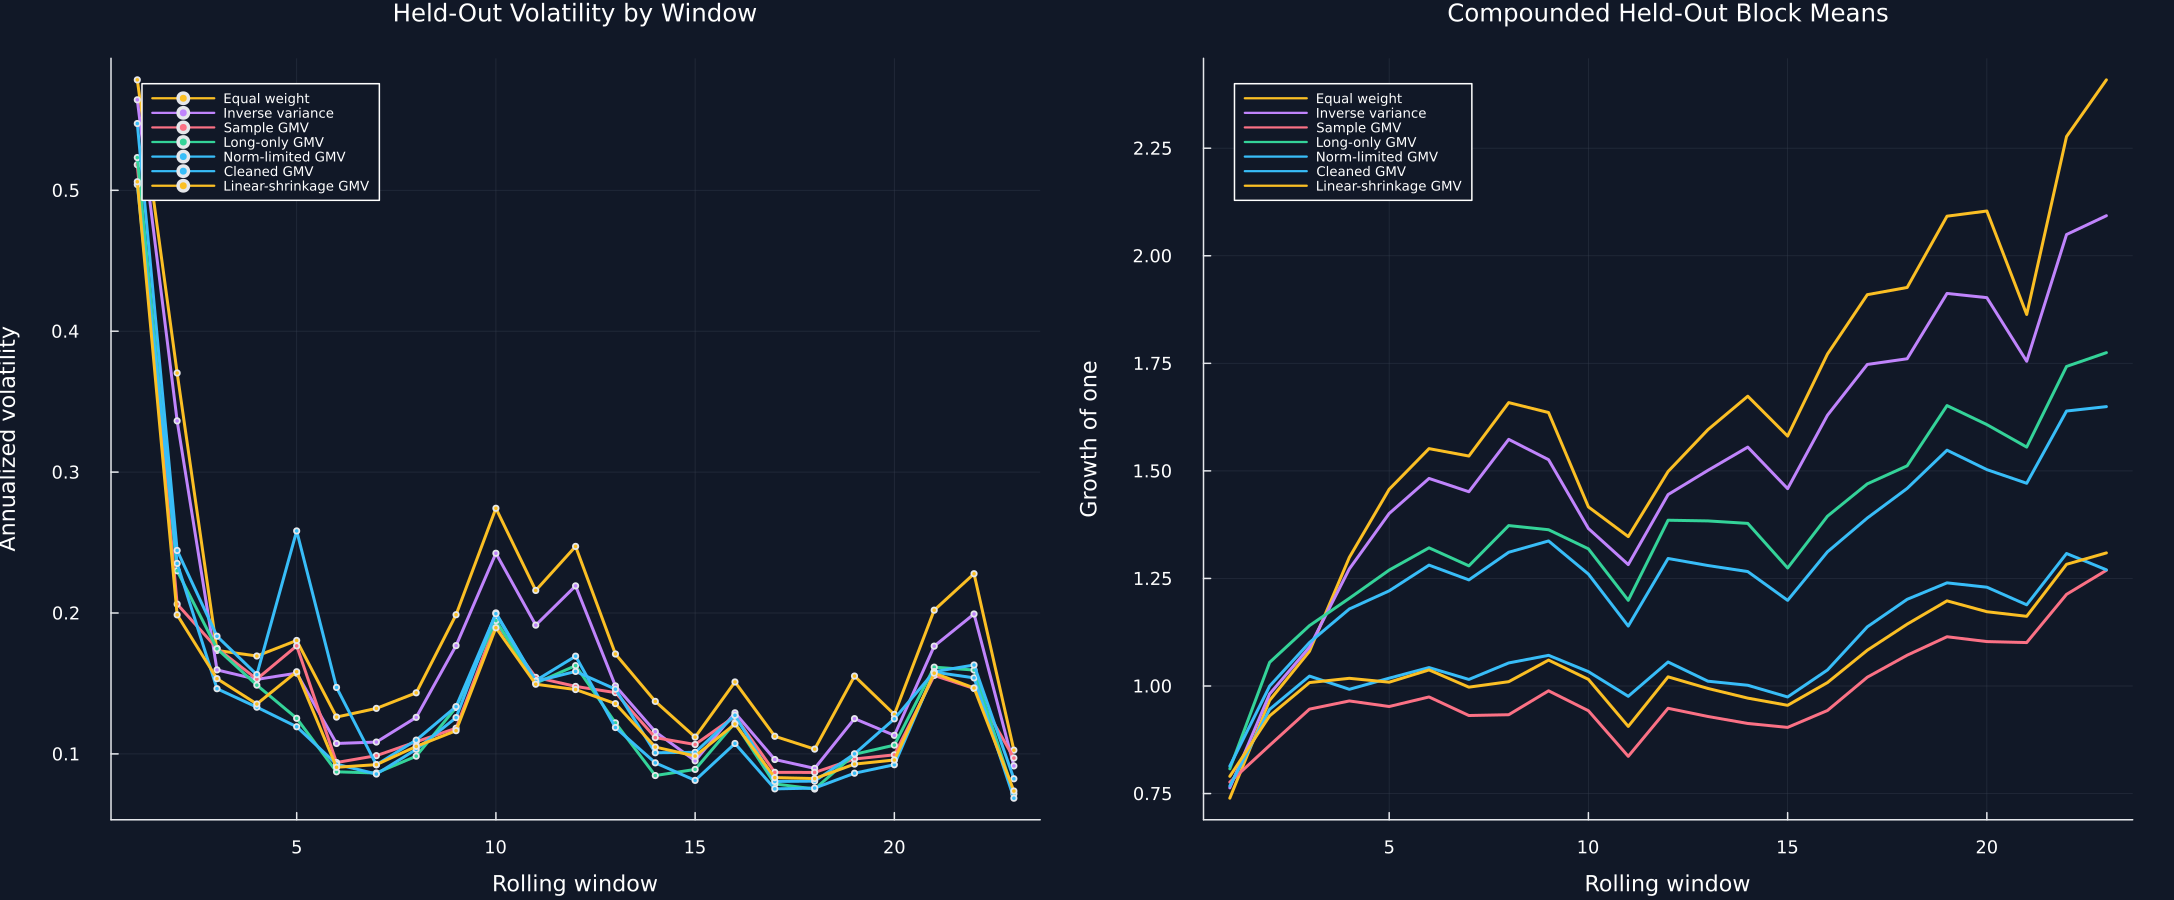

In [2]:
equal_risk = rolling_results[rolling_results.Method.=="Equal weight","Annualized test volatility"]
best_rows = NamedTuple[]
for fold in 1:fold_number
    group = rolling_results[rolling_results.Fold.==fold,:]
    push!(best_rows,(Fold=fold,Method=group.Method[argmin(group[!,"Annualized test volatility"])]))
end
best_by_fold = DataFrame(best_rows)
risk_rows,weight_rows = NamedTuple[],NamedTuple[]
for method in method_order
    group = rolling_results[rolling_results.Method.==method,:]
    risk = group[!,"Annualized test volatility"]
    push!(risk_rows,(method=method,annual_return=mean(group[!,"Annualized test return"]),volatility=mean(risk),median_volatility=median(risk),sharpe=mean(group[!,"Test Sharpe ratio"]),ratio=mean(risk./equal_risk),below=count(risk.<equal_risk),best=count(==(method),best_by_fold.Method)))
    push!(weight_rows,(method=method,gross=median(group[!,"Gross exposure"]),largest=median(group[!,"Largest absolute weight"]),effective=median(group[!,"Effective holdings"]),turnover=mean(filter(isfinite,group.Turnover)),smallest=minimum(group[!,"Smallest weight"])))
end
rolling_risk_summary,rolling_weight_summary = DataFrame(risk_rows),DataFrame(weight_rows)
rename!(rolling_risk_summary,["Method","Mean annualized return","Mean annualized volatility","Median annualized volatility","Mean test Sharpe ratio","Mean volatility ratio to equal weight","Folds below equal-weight volatility","Lowest-volatility folds"])
rename!(rolling_weight_summary,["Method","Median gross exposure","Median largest absolute weight","Median effective holdings","Mean turnover","Smallest observed weight"])
winner_methods = unique(best_by_fold.Method)
winner_counts = [count(==(method),best_by_fold.Method) for method in winner_methods]
winner_order = sortperm(winner_counts;rev=true,alg=MergeSort)
fold_winners = DataFrame("Method"=>winner_methods[winner_order],"Lowest-volatility folds"=>winner_counts[winner_order])
table(rolling_risk_summary,"rolling_risk_summary","Held-out risk and return across public rolling windows.")
table(rolling_weight_summary,"rolling_weight_summary","Weight size, spread, and turnover across public rolling windows.")
table(fold_winners,"rolling_fold_winners","Counts of the lowest-volatility method in each public test window.")
save_data(best_by_fold,paths,"best_by_fold")
method_colors = [palette.amber,violet,palette.rose,palette.green,palette.cyan,"#38BDF8","#FBBF24"]
p1 = plot(;title="Held-Out Volatility by Window",xlabel="Rolling window",ylabel="Annualized volatility",legend=:topleft,legendfontsize=6)
p2 = plot(;title="Compounded Held-Out Block Means",xlabel="Rolling window",ylabel="Growth of one",legend=:topleft,legendfontsize=6)
cumulative_rows = NamedTuple[]
for (method,color) in zip(method_order,method_colors)
    group = rolling_results[rolling_results.Method.==method,:]
    plot!(p1,group.Fold,group[!,"Annualized test volatility"];color,marker=:circle,markersize=2,label=method)
    growth = cumprod(exp.(group[!,"Annualized test return"].*testing_days./252))
    plot!(p2,group.Fold,growth;color,label=method)
    append!(cumulative_rows,[(fold=fold,method=method,growth=value) for (fold,value) in enumerate(growth)])
end
save_data(DataFrame(cumulative_rows),paths,"cumulative_paths")
save_figure(plot(p1,p2;layout=(1,2),size=(1450,600)),paths,"rolling_risk_return_paths")


## Diagnosing portfolio implementation

Weight concentration can be read as an effective number of equally weighted holdings:

$$
H(w)=\sum_{i=1}^{N}w_i^2,
\qquad
N_{\mathrm{eff}}(w)=\frac{1}{H(w)}.
$$

Here, $N$ is the number of assets, $H(w)$ is the squared-weight concentration, and $N_{\mathrm{eff}}(w)$ is the number of equal weights that would produce the same concentration. Negative weights also raise $H(w)$ because they enter as squares.

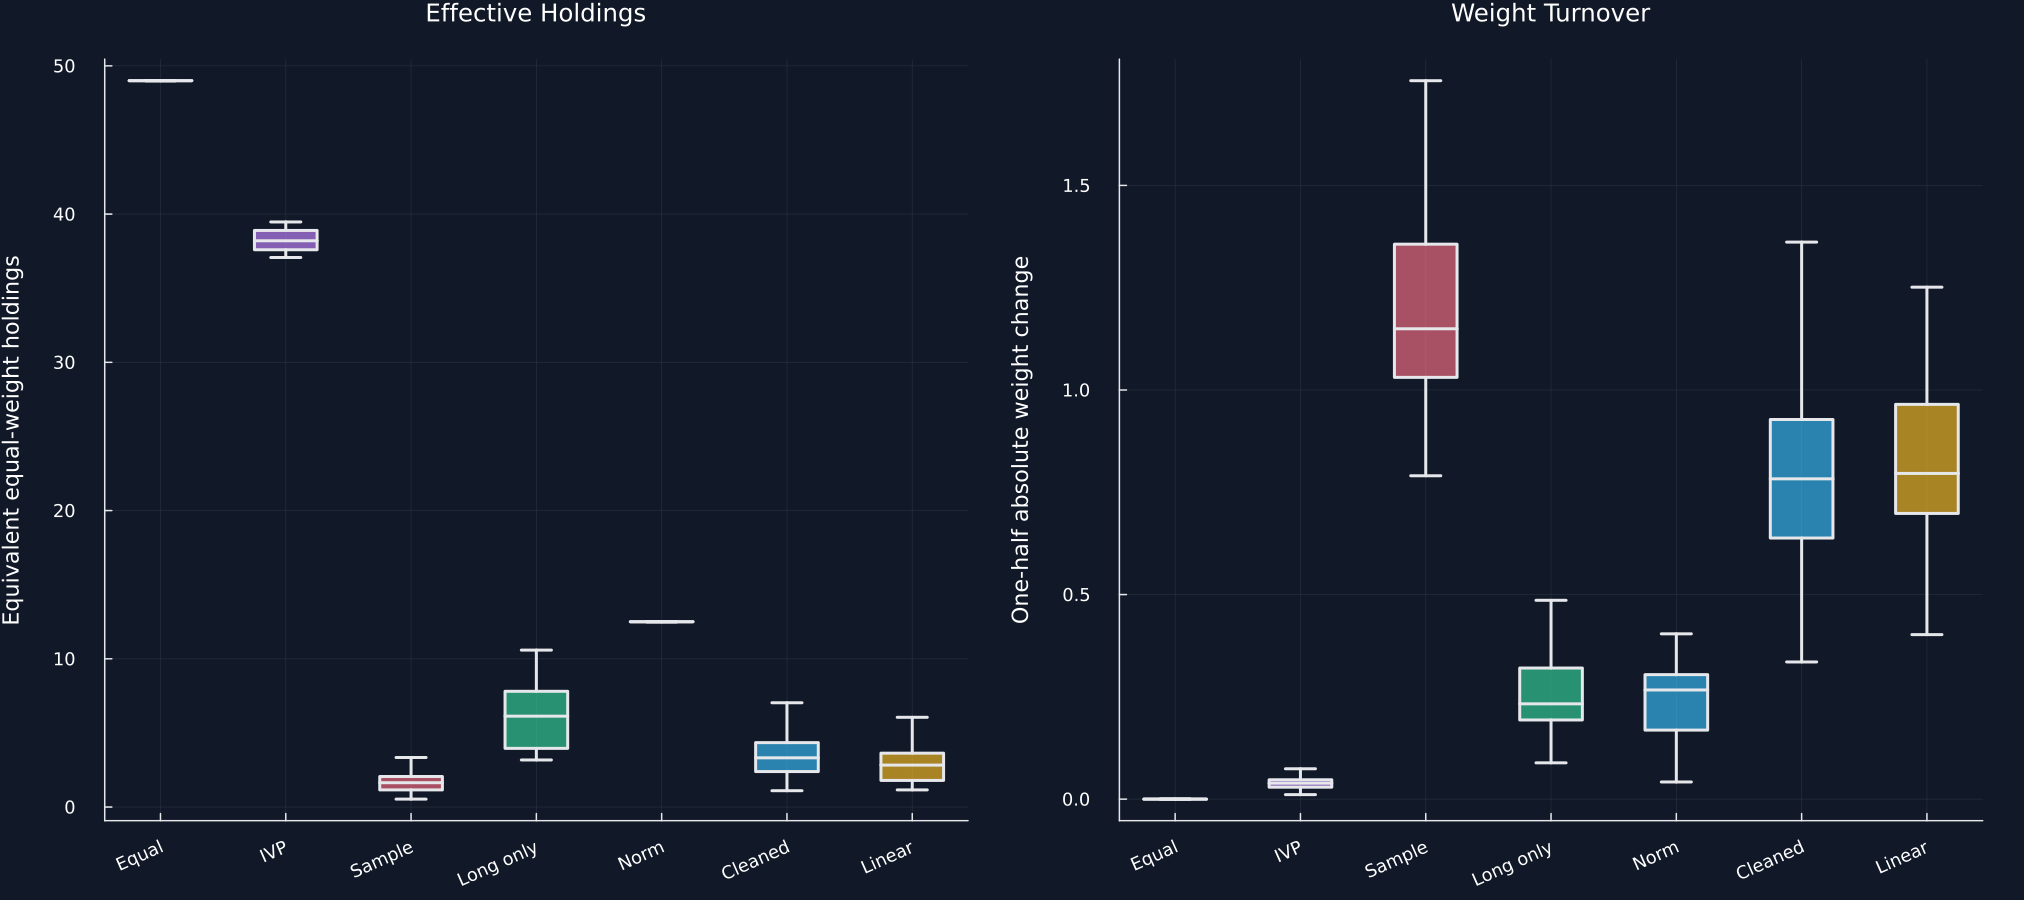

In [3]:
short_labels = ["Equal","IVP","Sample","Long only","Norm","Cleaned","Linear"]
p1 = plot(;title="Effective Holdings",ylabel="Equivalent equal-weight holdings",xticks=(1:7,short_labels),xrotation=24,legend=false)
p2 = plot(;title="Weight Turnover",ylabel="One-half absolute weight change",xticks=(1:7,short_labels),xrotation=24,legend=false)
box_summary!(p1,[rolling_results[rolling_results.Method.==method,"Effective holdings"] for method in method_order],method_colors)
box_summary!(p2,[filter(isfinite,rolling_results[rolling_results.Method.==method,"Turnover"]) for method in method_order],method_colors)
save_figure(plot(p1,p2;layout=(1,2),size=(1350,600)),paths,"rolling_concentration_turnover")


## Stress-testing portfolio dimension

A stress ratio compares each method with equal weighting on the same held-out dates and asset set:

$$
S_{m}(T,N)
=\frac{\operatorname{sd}(R_{T,N}^{\mathrm{test}}w_{m,T,N})}{\operatorname{sd}(R_{T,N}^{\mathrm{test}}w_{\mathrm{EW},N})}.
$$

Here, $T$ is the number of training days, $N$ is the number of included industries, $R_{T,N}^{\mathrm{test}}$ is the common held-out return matrix, $w_{m,T,N}$ is the weight vector from method $m$, and $w_{\mathrm{EW},N}$ is the equal-weight vector. A ratio below one means lower volatility in that particular held-out block.

Row,Method,Mean volatility ratio,Smallest volatility ratio,Largest volatility ratio,Mean gross exposure,Mean effective holdings
,String,Float64,Float64,Float64,Float64,Float64
1,Equal weight,1.0,1.0,1.0,1.0,30.3333
2,Sample GMV,0.909513,0.670807,1.30367,2.80568,2.99197
3,Long-only GMV,0.797515,0.686563,0.955187,1.0,7.41981
4,Norm-limited GMV,0.809078,0.67993,1.0,1.29252,12.3333
5,Cleaned GMV,0.826654,0.678095,0.965607,1.95194,4.68765


Row,Training days,Industries,Method,Covariance condition number,Annualized test volatility,Volatility ratio to equal weight,Gross exposure,Effective holdings
,Int64,Int64,String,Float64,Float64,Float64,Float64,Float64
1,126,12,Equal weight,101.736,0.102279,1.0,1.0,12.0
2,126,12,Sample GMV,101.736,0.102442,1.00159,1.5394,3.16312
3,126,12,Long-only GMV,101.736,0.0976958,0.955187,1.0,5.96084
4,126,12,Norm-limited GMV,101.736,0.102279,1.0,1.0,12.0
5,126,12,Cleaned GMV,101.736,0.0980519,0.958669,1.36525,4.77729
6,126,30,Equal weight,589.864,0.121535,1.0,1.0,30.0
7,126,30,Sample GMV,589.864,0.112204,0.923226,3.17327,1.49575
8,126,30,Long-only GMV,589.864,0.0937615,0.771479,1.0,6.45818
9,126,30,Norm-limited GMV,589.864,0.0908762,0.747738,1.22502,12.5


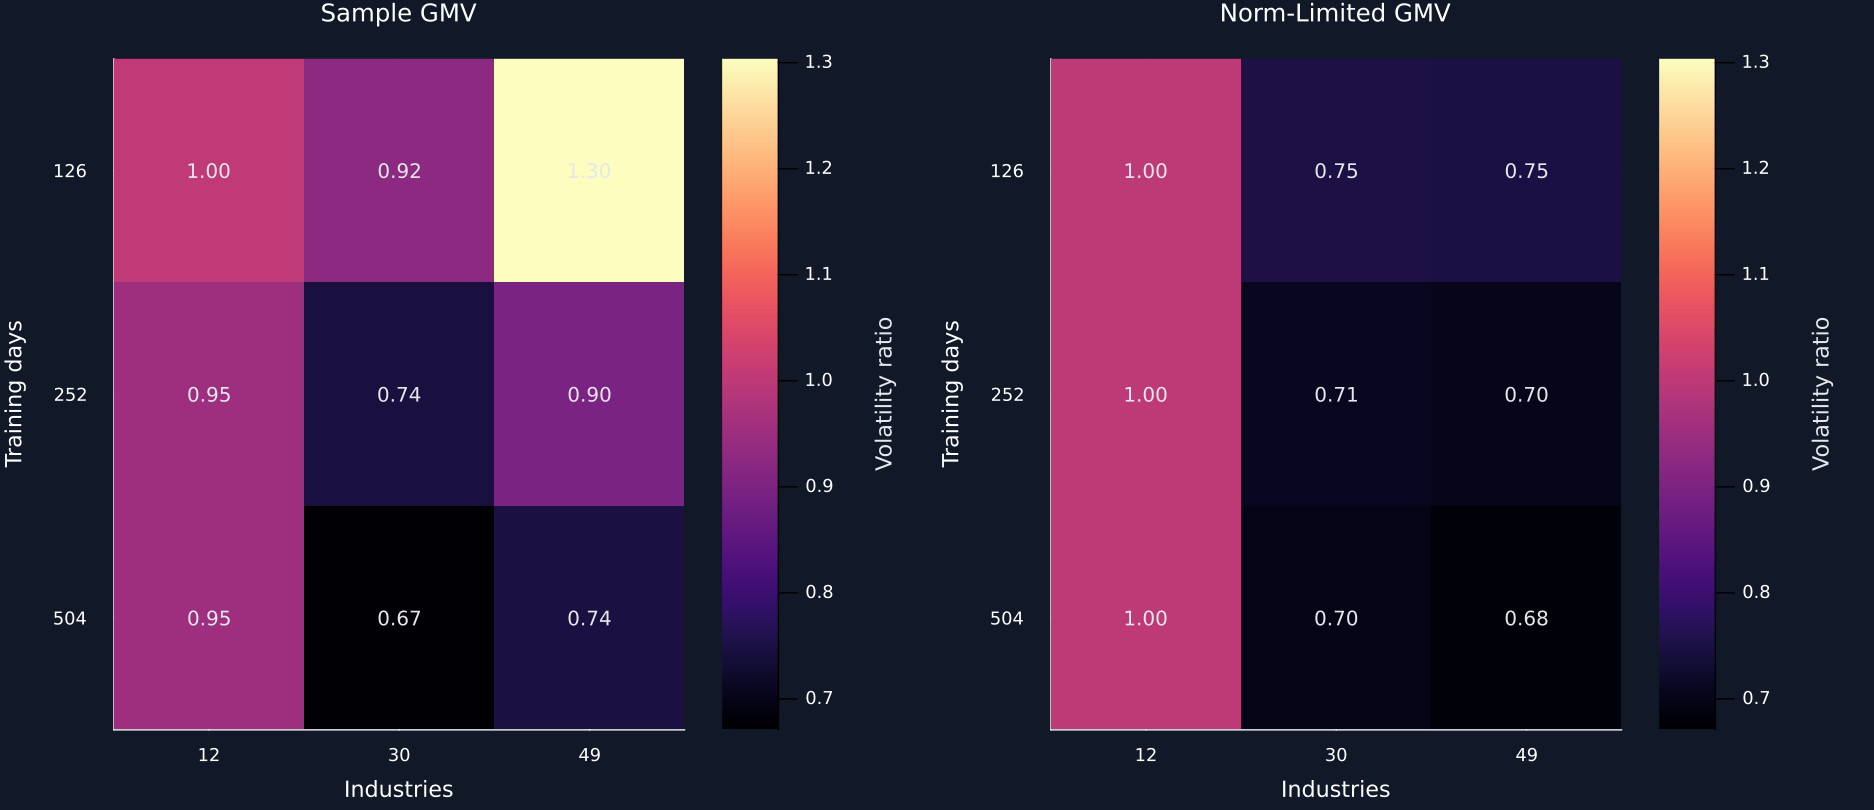

In [4]:
stress_training_days,stress_asset_counts,stress_testing_days = [126,252,504],[12,30,49],126
stress_test = industry_returns[end-stress_testing_days+1:end,:]
stress_rows,stress_weights = NamedTuple[],DataFrame[]
stress_methods = ["Equal weight","Sample GMV","Long-only GMV","Norm-limited GMV","Cleaned GMV"]
for train_length in stress_training_days
    stress_training = industry_returns[end-stress_testing_days-train_length+1:end-stress_testing_days,:]
    for asset_count in stress_asset_counts
        training,testing = stress_training[:,1:asset_count],stress_test[:,1:asset_count]
        covariance = cov(training)
        name = "stress_"*string(train_length)*"_"*string(asset_count)
        cleaned = save_noise_fit(covariance,train_length/asset_count,name*"_noise_fit")
        equal_weights = fill(1/asset_count,asset_count)
        method_weights = [equal_weights,global_minimum_variance(covariance),long_only_minimum_variance(covariance),norm_limited_minimum_variance(covariance,max(.08,1/asset_count)),global_minimum_variance(cleaned)]
        equal_volatility = std(testing*equal_weights)*sqrt(252)
        save_data(matrix_frame(covariance),paths,name*"_covariance")
        save_data(matrix_frame(cleaned),paths,name*"_cleaned")
        for (method,weights) in zip(stress_methods,method_weights)
            volatility = std(testing*weights)*sqrt(252)
            push!(stress_rows,(training_days=train_length,industries=asset_count,method=method,condition=cond(covariance),volatility=volatility,ratio=volatility/equal_volatility,gross=sum(abs,weights),effective=1/sum(abs2,weights)))
            push!(stress_weights,weight_frame(weights;training_days=train_length,industries=asset_count,method))
        end
    end
end
training_asset_stress = DataFrame(stress_rows)
rename!(training_asset_stress,["Training days","Industries","Method","Covariance condition number","Annualized test volatility","Volatility ratio to equal weight","Gross exposure","Effective holdings"])
stress_summary = DataFrame([(method=method,mean_ratio=mean(group[!,"Volatility ratio to equal weight"]),smallest=minimum(group[!,"Volatility ratio to equal weight"]),largest=maximum(group[!,"Volatility ratio to equal weight"]),gross=mean(group[!,"Gross exposure"]),effective=mean(group[!,"Effective holdings"])) for method in stress_methods for group in [training_asset_stress[training_asset_stress.Method.==method,:]]])
rename!(stress_summary,["Method","Mean volatility ratio","Smallest volatility ratio","Largest volatility ratio","Mean gross exposure","Mean effective holdings"])
table(stress_summary,"training_asset_stress_summary","Portfolio behavior across training lengths and asset counts.")
table(training_asset_stress,"training_asset_stress_audit","Complete training-length and asset-count stress results.")
save_data(reduce(vcat,stress_weights),paths,"stress_weights")
heat_matrices = [reshape(training_asset_stress[training_asset_stress.Method.==method,"Volatility ratio to equal weight"],3,3)' for method in ["Sample GMV","Norm-limited GMV"]]
color_limits = (minimum(minimum.(heat_matrices)),maximum(maximum.(heat_matrices)))
panels = []
for (values,title) in zip(heat_matrices,["Sample GMV","Norm-Limited GMV"])
    figure = heatmap(1:3,1:3,values;color=:magma,clims=color_limits,xticks=(1:3,string.(stress_asset_counts)),yticks=(1:3,string.(stress_training_days)),yflip=true,title,xlabel="Industries",ylabel="Training days",colorbar_title="Volatility ratio",xlims=(.5,3.5),ylims=(.5,3.5),widen=false)
    for row in 1:3,column in 1:3
        annotate!(figure,column,row,text(@sprintf("%.2f",values[row,column]),9,palette.text))
    end
    push!(panels,figure)
end
save_figure(plot(panels...;layout=(1,2),size=(1250,540)),paths,"training_asset_stress_heatmaps")


## Diagnosing sources of portfolio error

A portfolio shock diagnostic reports weight movement and held-out risk relative to an unshocked choice:

$$
D_w(a)=\lVert w(a)-w(0)\rVert_1,
\qquad
D_\sigma(a)=\frac{\operatorname{sd}(R^{\mathrm{test}}w(a))}{\operatorname{sd}(R^{\mathrm{test}}w(0))}.
$$

Here, $a$ is the declared shock size, $w(0)$ is the portfolio before the shock, $w(a)$ is the shocked portfolio, $D_w(a)$ is absolute weight movement, $R^{\mathrm{test}}$ is the unchanged held-out return matrix, and $D_\sigma(a)$ is its volatility ratio.

Row,Shock type,Shock size,Weight absolute change,Held-out volatility ratio,Gross exposure
,String,Float64,Float64,Float64,Float64
1,Covariance toward diagonal,0.1,1.98751,0.808531,2.79534
2,Covariance toward diagonal,0.25,2.82806,0.757706,2.08216
3,Covariance toward diagonal,0.5,3.43827,0.775688,1.48886
4,Expected return,0.1,1.31736,1.00146,6.79872
5,Expected return,0.25,3.41986,1.02266,7.00547
6,Expected return,0.5,7.30742,1.11762,7.99328


Row,Shock type,Shock size,Weight absolute change,Held-out volatility ratio,Gross exposure
,String,Float64,Float64,Float64,Float64
1,Covariance toward diagonal,0.0,0.0,1.0,4.27415
2,Covariance toward diagonal,0.05,1.3619,0.864721,3.25131
3,Covariance toward diagonal,0.1,1.98751,0.808531,2.79534
4,Covariance toward diagonal,0.15,2.36864,0.779551,2.50148
5,Covariance toward diagonal,0.2,2.63229,0.764524,2.2717
6,Covariance toward diagonal,0.25,2.82806,0.757706,2.08216
7,Covariance toward diagonal,0.3,2.99008,0.756097,1.92364
8,Covariance toward diagonal,0.35,3.12649,0.757968,1.78971
9,Covariance toward diagonal,0.4,3.24659,0.762263,1.67359


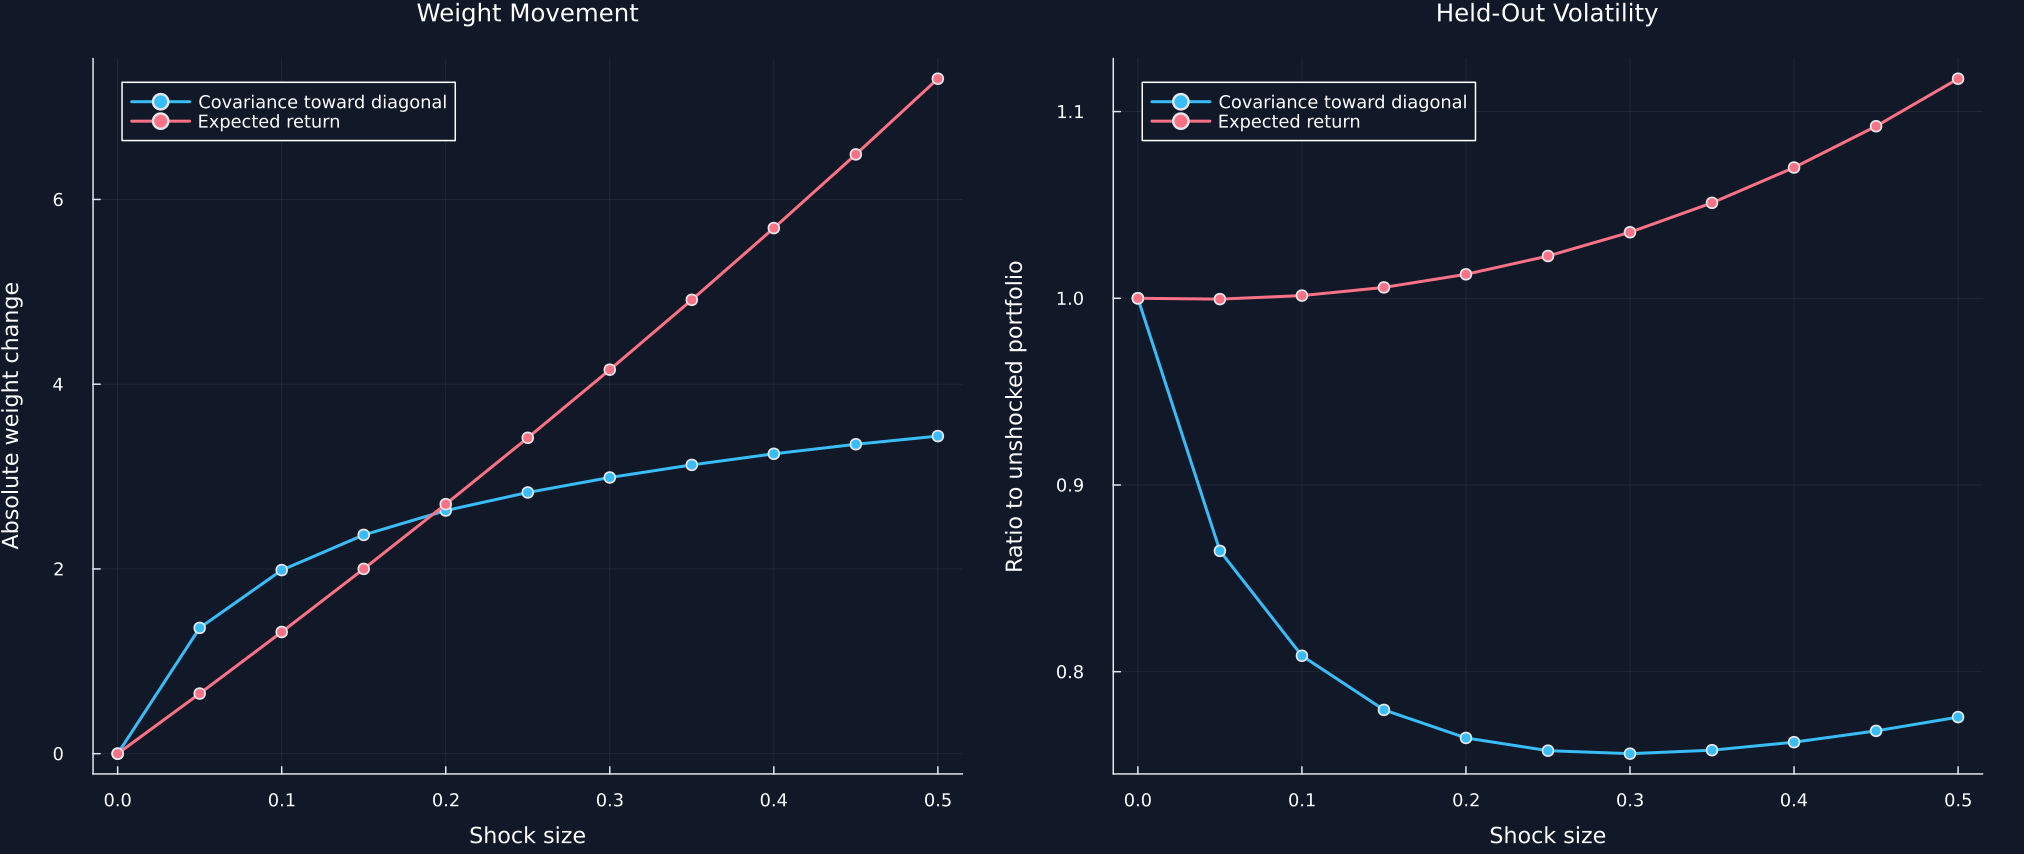

In [5]:
shock_training,shock_testing = industry_returns[end-377:end-126,:],industry_returns[end-125:end,:]
shock_covariance = cov(shock_training)
shock_diagonal = Diagonal(diag(shock_covariance))
base_shock_weights = global_minimum_variance(shock_covariance)
base_shock_volatility = std(shock_testing*base_shock_weights)
shock_rows = NamedTuple[]
shock_weight_rows = DataFrame[]
for level in range(0.,.5;length=11)
    covariance = (1-level)*shock_covariance+level*shock_diagonal
    weights = global_minimum_variance(covariance)
    push!(shock_rows,(type="Covariance toward diagonal",size=level,change=sum(abs,weights-base_shock_weights),ratio=std(shock_testing*weights)/base_shock_volatility,gross=sum(abs,weights)))
    push!(shock_weight_rows,weight_frame(weights;type="Covariance toward diagonal",level))
end
mean_training,mean_testing = shock_training[:,1:12],shock_testing[:,1:12]
mean_covariance,estimated_mean = cov(mean_training),vec(mean(mean_training;dims=1))
base_mean_weights = mean_return_weighted(mean_covariance,estimated_mean)
base_mean_volatility = std(mean_testing*base_mean_weights)
mean_direction = collect(range(-1.,1.;length=12))
mean_direction .-= mean(mean_direction)
mean_direction ./= norm(mean_direction)
for level in range(0.,.5;length=11)
    weights = mean_return_weighted(mean_covariance,estimated_mean+level*norm(estimated_mean)*mean_direction)
    push!(shock_rows,(type="Expected return",size=level,change=sum(abs,weights-base_mean_weights),ratio=std(mean_testing*weights)/base_mean_volatility,gross=sum(abs,weights)))
    push!(shock_weight_rows,weight_frame(weights;type="Expected return",level))
end
shock_paths = DataFrame(shock_rows)
rename!(shock_paths,["Shock type","Shock size","Weight absolute change","Held-out volatility ratio","Gross exposure"])
shock_summary = shock_paths[in.(shock_paths[!,"Shock size"],Ref([.1,.25,.5])),:]
table(shock_summary,"portfolio_shock_summary","Held-out effects of declared covariance and expected-return shocks.")
table(shock_paths,"portfolio_shock_audit","Complete covariance and expected-return shock paths.")
save_data(reduce(vcat,shock_weight_rows;cols=:union),paths,"shock_weights")
p1 = plot(;title="Weight Movement",xlabel="Shock size",ylabel="Absolute weight change",legend=:topleft)
p2 = plot(;title="Held-Out Volatility",xlabel="Shock size",ylabel="Ratio to unshocked portfolio",legend=:topleft)
for (kind,color) in [("Covariance toward diagonal",palette.cyan),("Expected return",palette.rose)]
    group = shock_paths[shock_paths[!,"Shock type"].==kind,:]
    plot!(p1,group[!,"Shock size"],group[!,"Weight absolute change"];color,marker=:circle,label=kind)
    plot!(p2,group[!,"Shock size"],group[!,"Held-out volatility ratio"];color,marker=:circle,label=kind)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1350,570)),paths,"portfolio_shock_diagnostics")


## Tests

In [6]:
@assert size(industry_returns)==(1760,49)
@assert fold_number>15
@assert nrow(rolling_results)==fold_number*7
@assert all(count(==(method),rolling_results.Method)==fold_number for method in method_order)
@assert all(isapprox.(rolling_results[!,"Weight sum"],1.))
@assert all(rolling_results[!,"Annualized test volatility"].>0)
@assert all(rolling_results[!,"Effective holdings"].>0)
@assert minimum(rolling_results[rolling_results.Method.=="Long-only GMV","Smallest weight"])>=-1e-8
@assert maximum(rolling_results[rolling_results.Method.=="Norm-limited GMV","Weight concentration"])<=norm_limit+1e-7
@assert nrow(best_by_fold)==length(unique(best_by_fold.Fold))==fold_number
@assert sum(rolling_risk_summary[!,"Lowest-volatility folds"])==fold_number
@assert nrow(training_asset_stress)==45
@assert all(count((training_asset_stress[!,"Training days"].==duration).&(training_asset_stress.Industries.==assets))==5 for duration in stress_training_days for assets in stress_asset_counts)
@assert all(isapprox.(training_asset_stress[training_asset_stress.Method.=="Equal weight","Volatility ratio to equal weight"],1.))
@assert nrow(shock_paths)==22
@assert maximum(shock_paths[shock_paths[!,"Shock size"].==0.,"Weight absolute change"])<1e-10
@assert maximum(abs,shock_paths[shock_paths[!,"Shock size"].==0.,"Held-out volatility ratio"].-1)<1e-10
@assert length(unique(benchmark_definitions.Method))==7
@assert isfile(joinpath(paths.figures,"rolling_risk_return_paths.pdf"))
@assert isfile(joinpath(paths.figures,"rolling_concentration_turnover.pdf"))
@assert isfile(joinpath(paths.figures,"training_asset_stress_heatmaps.pdf"))
@assert isfile(joinpath(paths.figures,"portfolio_shock_diagnostics.pdf"))
@assert isfile(joinpath(paths.tables,"rolling_risk_summary.tex"))
@assert isfile(joinpath(paths.tables,"portfolio_shock_summary.tex"))
